In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix, roc_curve, auc, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

x_train = pd.read_csv("A5_2026_train.csv")
y_train = pd.read_csv("A5_2026_train_labels.csv", index_col=0)
x_test = pd.read_csv("A5_2026_test.csv")

# ExtraTrees with broad Optuna search + focused second-stage baseline search

SEED = 42
np.random.seed(SEED)
BROAD_TRIALS = 50
FOCUSED_TRIALS = 30
TOP_FRACTION = 0.2
MIN_TOP_TRIALS = 8
THRESHOLD_GRID = np.linspace(0.05, 0.95, 181)

# 1) Transform labels to binary format and identify positive/negative classes
y_str = y_train["label"].astype(str)
labels_sorted = sorted(y_str.unique())
if len(labels_sorted) != 2:
    raise ValueError(f"Expected binary labels, got: {labels_sorted}")

if "positive" in labels_sorted and "negative" in labels_sorted:
    pos_label, neg_label = "positive", "negative"
else:
    neg_label, pos_label = labels_sorted[0], labels_sorted[1]

y = y_str.to_numpy()
y_bin = (y == pos_label).astype(int)

# 2) CV protocol aligned with competition objective (BCR proxy)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
cv_splits = list(cv.split(x_train, y_bin))

# Building a function to create the extratree model pipeline with given hyperparameters
def build_model(params):
    return Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            (
                "model",
                ExtraTreesClassifier(
                    n_estimators=params["n_estimators"],
                    max_depth=params["max_depth"],
                    min_samples_split=params["min_samples_split"],
                    min_samples_leaf=params["min_samples_leaf"],
                    max_features=params["max_features"],
                    bootstrap=params["bootstrap"],
                    max_samples=params.get("max_samples"),
                    ccp_alpha=params["ccp_alpha"],
                    class_weight=params["class_weight"],
                    criterion=params["criterion"],
                    min_weight_fraction_leaf=params["min_weight_fraction_leaf"],
                    min_impurity_decrease=params["min_impurity_decrease"],
                    random_state=SEED,
                    n_jobs=-1,
                ),
            ),
        ]
    )

# Function to calibrate decision threshold based on BCR on validation data
def calibrate_threshold(y_true, y_proba, threshold_grid=None):
    if threshold_grid is None:
        threshold_grid = THRESHOLD_GRID

    best_threshold = 0.5
    best_bcr = -np.inf

    for th in threshold_grid:
        y_hat = (y_proba >= th).astype(int)
        bcr = balanced_accuracy_score(y_true, y_hat)
        if bcr > best_bcr:
            best_bcr = bcr
            best_threshold = float(th)

    return best_threshold, float(best_bcr)

# Function to evaluate a given set of hyperparameters using CV and return mean BCR, fold scores and optimal threshold
def evaluate_params(params, return_scores=False, return_threshold=False):
    fold_targets = []
    fold_probas = []

    for tr_idx, va_idx in cv_splits:
        X_tr = x_train.iloc[tr_idx]
        y_tr = y_bin[tr_idx]
        X_va = x_train.iloc[va_idx]
        y_va = y_bin[va_idx]

        model = build_model(params)
        model.fit(X_tr, y_tr)
        y_proba = model.predict_proba(X_va)[:, 1]

        fold_targets.append(y_va)
        fold_probas.append(y_proba)

    all_targets = np.concatenate(fold_targets)
    all_probas = np.concatenate(fold_probas)
    best_threshold, _ = calibrate_threshold(all_targets, all_probas)

    fold_scores = []
    for y_va, y_proba in zip(fold_targets, fold_probas):
        y_hat = (y_proba >= best_threshold).astype(int)
        fold_scores.append(balanced_accuracy_score(y_va, y_hat))

    fold_scores = np.asarray(fold_scores, dtype=float)
    mean_score = float(fold_scores.mean())

    if return_scores and return_threshold:
        return mean_score, fold_scores, best_threshold
    if return_scores:
        return mean_score, fold_scores
    if return_threshold:
        return mean_score, best_threshold
    return mean_score

# Function to suggest hyperparameters for Optuna trials
def suggest_params(trial, search_space=None):
    if search_space is None:
        bootstrap_choices = [False, True]
        n_estimators_low, n_estimators_high, n_estimators_step = 1200, 3200, 50
        max_depth_choices = [6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 28, 32, None]
        min_split_low, min_split_high = 5, 60
        min_leaf_low, min_leaf_high = 1, 30
        max_features_choices = [
    "sqrt", "log2", 0.5, 0.6,
    0.7, 0.8, 0.9, 1.0, None]
        ccp_low, ccp_high = 0.0, 0.02
        criterion_choices = ["gini", "entropy", "log_loss"]
        mwfl_low, mwfl_high = 0.0, 0.2
        mid_low, mid_high = 0.0, 0.02
        max_samples_low, max_samples_high = 0.2, 1.0
        class_weight_choices = ["balanced", "balanced_subsample", None]
    else:
        bootstrap_choices = search_space["bootstrap"]
        n_estimators_low, n_estimators_high, n_estimators_step = search_space["n_estimators"]
        max_depth_choices = search_space["max_depth"]
        min_split_low, min_split_high = search_space["min_samples_split"]
        min_leaf_low, min_leaf_high = search_space["min_samples_leaf"]
        max_features_choices = search_space["max_features"]
        ccp_low, ccp_high = search_space["ccp_alpha"]
        criterion_choices = search_space["criterion"]
        mwfl_low, mwfl_high = search_space["min_weight_fraction_leaf"]
        mid_low, mid_high = search_space["min_impurity_decrease"]
        max_samples_low, max_samples_high = search_space["max_samples"]
        class_weight_choices = search_space.get("class_weight", ["balanced", "balanced_subsample", None])

    bootstrap = trial.suggest_categorical("bootstrap", bootstrap_choices)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", n_estimators_low, n_estimators_high, step=n_estimators_step),
        "max_depth": trial.suggest_categorical("max_depth", max_depth_choices),
        "min_samples_split": trial.suggest_int("min_samples_split", min_split_low, min_split_high),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", min_leaf_low, min_leaf_high),
        "max_features": trial.suggest_categorical("max_features", max_features_choices),
        "bootstrap": bootstrap,
        "max_samples": trial.suggest_float("max_samples", max_samples_low, max_samples_high) if bootstrap else None,
        "ccp_alpha": trial.suggest_float("ccp_alpha", ccp_low, ccp_high),
        "criterion": trial.suggest_categorical("criterion", criterion_choices),
        "min_weight_fraction_leaf": trial.suggest_float("min_weight_fraction_leaf", mwfl_low, mwfl_high),
        "min_impurity_decrease": trial.suggest_float("min_impurity_decrease", mid_low, mid_high),
        "class_weight": trial.suggest_categorical("class_weight", class_weight_choices),
    }
    return params

# Objective function for Optuna optimization
def make_objective(search_space=None):
    def objective(trial):
        params = suggest_params(trial, search_space=search_space)
        return evaluate_params(params)

    return objective

# Helper functions to build focused search space from top broad trials
def _top_trials(study, top_fraction=TOP_FRACTION, min_top=MIN_TOP_TRIALS):
    completed = [t for t in study.trials if t.value is not None and t.params]
    if not completed:
        return []
    completed.sort(key=lambda t: t.value, reverse=True)
    n_top = int(np.ceil(len(completed) * top_fraction))
    n_top = max(min_top, n_top)
    n_top = min(len(completed), n_top)
    return completed[:n_top]

# Preserve order while extracting unique values from a list
def _ordered_unique(values):
    out = []
    for v in values:
        if v not in out:
            out.append(v)
    return out

# Focus on the most common values of hyperparamters among top trials but ensure at least min_choices are retained
def _focused_choices(values, fallback_choices, min_choices=2):
    top_unique = _ordered_unique(values)
    if not top_unique:
        return list(fallback_choices)

    focused = [c for c in fallback_choices if c in top_unique]
    if len(focused) >= min_choices:
        return focused

    for c in fallback_choices:
        if c not in focused:
            focused.append(c)
        if len(focused) >= min_choices:
            break
    return focused

# Focus on the interquantile range of top trials but ensure it stays within global bounds and has a reasonable width
def _int_bounds(values, global_low, global_high, pad=2):
    arr = np.asarray(values, dtype=float)
    lo = int(np.floor(np.quantile(arr, 0.1))) - pad
    hi = int(np.ceil(np.quantile(arr, 0.9))) + pad
    lo = max(global_low, lo)
    hi = min(global_high, hi)
    if lo >= hi:
        lo = max(global_low, int(np.floor(arr.min())))
        hi = min(global_high, int(np.ceil(arr.max())))
    if lo >= hi:
        hi = min(global_high, lo + 1)
    return lo, hi

# Similar to _int_bounds but for float values and with a pad ratio instead of fixed pad
def _float_bounds(values, global_low, global_high, pad_ratio=0.05):
    arr = np.asarray(values, dtype=float)
    lo = float(np.quantile(arr, 0.1))
    hi = float(np.quantile(arr, 0.9))
    pad = max((global_high - global_low) * pad_ratio, 1e-6)
    lo = max(global_low, lo - pad)
    hi = min(global_high, hi + pad)
    if lo >= hi:
        lo = max(global_low, float(arr.min()))
        hi = min(global_high, float(arr.max()))
    if lo >= hi:
        hi = min(global_high, lo + 1e-6)
    return lo, hi

# Main function to build a focused search space based on top trials from a broad Optuna study
def build_focused_space(study, top_fraction=TOP_FRACTION):
    top_trials = _top_trials(study, top_fraction=top_fraction)
    if not top_trials:
        return None

    p = [t.params for t in top_trials]

    n_lo, n_hi = _int_bounds([d["n_estimators"] for d in p], 600, 3200, pad=250)
    n_lo = max(600, int(np.floor(n_lo / 50) * 50))
    n_hi = min(3200, int(np.ceil(n_hi / 50) * 50))
    if n_hi <= n_lo:
        n_hi = min(3200, n_lo + 50)

    depth_choices = _focused_choices([d["max_depth"] for d in p], [6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 28, 32, None], min_choices=2)
    split_lo, split_hi = _int_bounds([d["min_samples_split"] for d in p], 2, 60, pad=3)
    leaf_lo, leaf_hi = _int_bounds([d["min_samples_leaf"] for d in p], 1, 30, pad=2)
    max_features_choices = _focused_choices(
        [d["max_features"] for d in p],
        ["sqrt", "log2", 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, None],
        min_choices=4,
    )
    bootstrap_choices = _focused_choices([d["bootstrap"] for d in p], [False, True], min_choices=1)

    max_samples_vals = [d["max_samples"] for d in p if d.get("max_samples") is not None]
    if max_samples_vals:
        ms_lo, ms_hi = _float_bounds(max_samples_vals, 0.2, 1.0, pad_ratio=0.12)
    else:
        ms_lo, ms_hi = 0.2, 1.0

    ccp_lo, ccp_hi = _float_bounds([d["ccp_alpha"] for d in p], 0.0, 0.02)
    criterion_choices = _focused_choices([d["criterion"] for d in p], ["gini", "entropy", "log_loss"], min_choices=2)
    mwfl_lo, mwfl_hi = _float_bounds([d["min_weight_fraction_leaf"] for d in p], 0.0, 0.2)
    mid_lo, mid_hi = _float_bounds([d["min_impurity_decrease"] for d in p], 0.0, 0.02)
    class_weight_choices = _focused_choices(
        [d.get("class_weight") for d in p if "class_weight" in d],
        ["balanced", "balanced_subsample", None],
        min_choices=1,
    )

    focused_space = {
        "bootstrap": bootstrap_choices,
        "n_estimators": (n_lo, n_hi, 50),
        "max_depth": depth_choices,
        "min_samples_split": (split_lo, split_hi),
        "min_samples_leaf": (leaf_lo, leaf_hi),
        "max_features": max_features_choices,
        "max_samples": (ms_lo, ms_hi),
        "ccp_alpha": (ccp_lo, ccp_hi),
        "criterion": criterion_choices,
        "min_weight_fraction_leaf": (mwfl_lo, mwfl_hi),
        "min_impurity_decrease": (mid_lo, mid_hi),
        "class_weight": class_weight_choices,
    }

    return focused_space


# 3) Hyperparameter tuning with Optuna (broad -> focused)

# Broad Optuna tuning for baseline extratrees
baseline_study = optuna.create_study(direction="maximize", study_name="a5_extratrees_baseline_broad")
baseline_study.optimize(make_objective(search_space=None), n_trials=BROAD_TRIALS, show_progress_bar=True)

# Build focused baseline search space from top broad trials
baseline_focused_space = build_focused_space(baseline_study, top_fraction=TOP_FRACTION)
print(baseline_focused_space)

# Focused Optuna tuning for baseline extratrees
baseline_focused_study = optuna.create_study(direction="maximize", study_name="a5_extratrees_baseline_focused")
baseline_focused_study.optimize(
    make_objective(search_space=baseline_focused_space),
    n_trials=FOCUSED_TRIALS,
    show_progress_bar=True,
)

# Getting results from focused baseline search and determine baseline expected BCR
baseline_best_trial = baseline_focused_study.best_trial
if baseline_study.best_trial.value > baseline_best_trial.value:
    baseline_best_trial = baseline_study.best_trial

baseline_params = dict(baseline_best_trial.params)
baseline_params["max_samples"] = baseline_params.get("max_samples") if baseline_params.get("bootstrap") else None
cv_mean_bcr, cv_scores, optimal_threshold = evaluate_params(baseline_params, return_scores=True, return_threshold=True)
cv_std_bcr = float(cv_scores.std(ddof=1))
sem_bcr = cv_std_bcr / np.sqrt(len(cv_scores))
expected_bcr_submission = float(np.clip(cv_mean_bcr - 0.5 * sem_bcr, 0.0, 1.0))

print(baseline_params)
print(f"Calibrated decision threshold: {optimal_threshold:.4f}")
print(f"Baseline CV mean BCR: {cv_mean_bcr:.5f}")
print(f"Baseline CV std BCR : {cv_std_bcr:.5f}")
print(f"First expected BCR: {expected_bcr_submission:.5f}")

# 4) Fit final model on all labeled data and generate required CSV 
final_model = build_model(baseline_params)
final_model.fit(x_train, y_bin)

y_test_proba = final_model.predict_proba(x_test)[:, 1]
y_test_pred = (y_test_proba >= optimal_threshold).astype(int)
y_pred = pd.Series(np.where(y_test_pred == 1, "positive", "negative"), index=x_test.index, name="label")
y_pred.to_csv("predictions_model3.csv", index=True)

# Keep values accessible report
best_cv_bcr = cv_mean_bcr
expected_bcr = expected_bcr_submission
best_threshold = optimal_threshold


Fixed baseline hyperparameters:
{'bootstrap': False, 'n_estimators': 2650, 'max_depth': 20, 'min_samples_split': 3, 'min_samples_leaf': 10, 'max_features': 0.5, 'ccp_alpha': 0.003017159373485624, 'criterion': 'entropy', 'min_weight_fraction_leaf': 0.0029893834009811155, 'min_impurity_decrease': 0.0015794251760939695, 'class_weight': 'balanced_subsample', 'max_samples': None}
Calibrated decision threshold: 0.2750
Baseline CV mean BCR: 0.77759
Baseline CV std BCR : 0.03228
Suggested expected BCR (Question 2): 0.77343
Saved predictions to predictions_model3.csv
Prediction class distribution:
label
negative    815
positive    185
Name: count, dtype: int64



STARTING PERFORMANCE ASSESSMENT


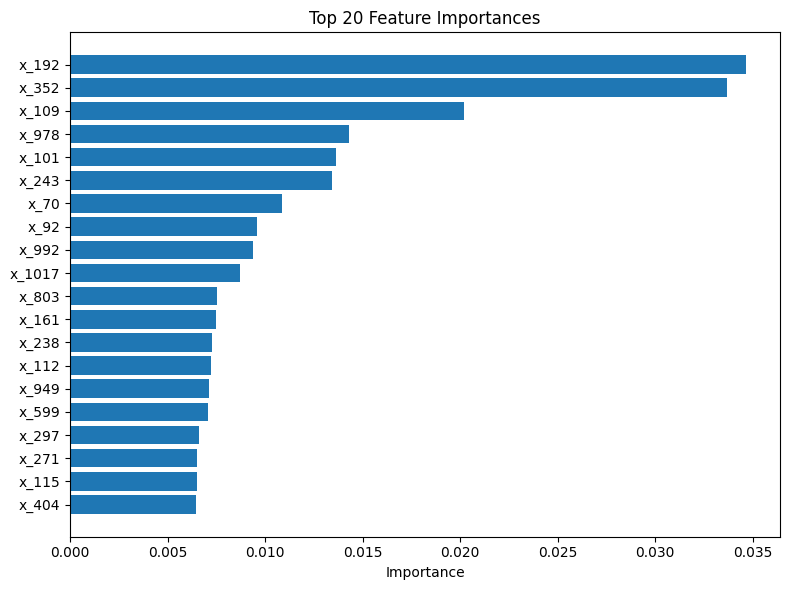


Generating repeated cross-validated predictions for detailed metrics...

--- Cross-Validated Classification Report ---
Using Calibrated Threshold: 0.2750
              precision    recall  f1-score   support

    negative       0.96      0.88      0.92      2700
    positive       0.39      0.69      0.50       300

    accuracy                           0.86      3000
   macro avg       0.67      0.78      0.71      3000
weighted avg       0.90      0.86      0.88      3000



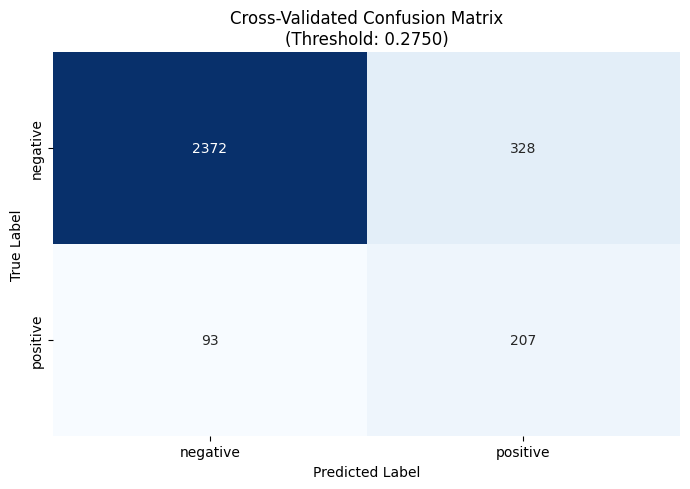

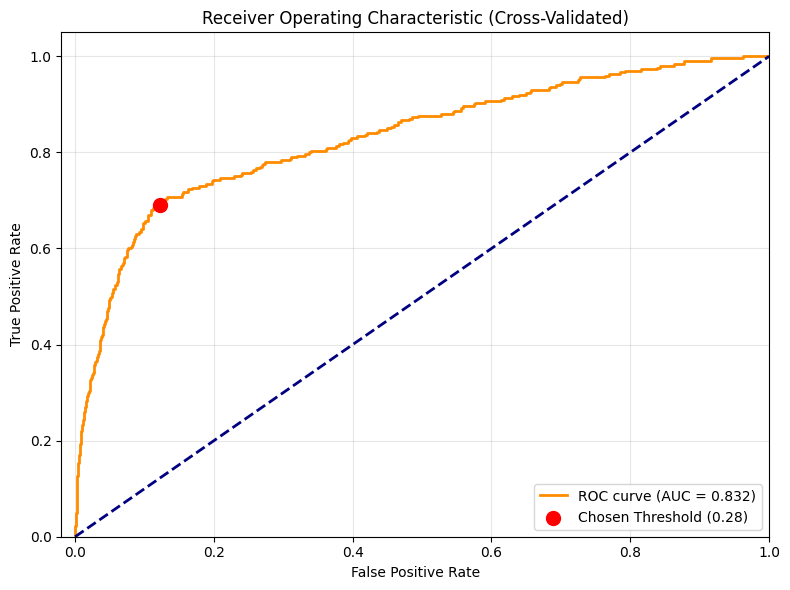

Validation comparison using repeated cross-validation:
          model  n_features  threshold    bcr    auc  bcr_retention_%  auc_retention_%
     Full model        1024     0.2750 0.7776 0.8320         100.0000         100.0000
Top 10 features          10     0.4700 0.7180 0.7542          92.3315          90.6519
 Top 5 features           5     0.5550 0.6954 0.6925          89.4261          83.2295


In [ ]:
# 5) Performance Assessment & Visualization

# Extract the extratrees model from the fitted final pipeline and analyze feature importances
et_model = final_model.named_steps["model"]
importances = et_model.feature_importances_
feature_names = x_train.columns

TOP_IMPORTANCE_N = 20

et_model = final_model.named_steps["model"]
importances = et_model.feature_importances_
if 'feature_names' in globals() and feature_names is not None:
    names = list(feature_names)
elif 'x_train' in globals():
    names = list(x_train.columns)
else:
    names = [f"f{i}" for i in range(len(importances))]

indices = np.argsort(importances)[::-1]
top_idx = indices[:TOP_IMPORTANCE_N]
top_feats = [names[i] for i in top_idx]
top_imps = importances[top_idx]

# # Make plot of feature importances
plt.figure(figsize=(8,6))
plt.barh(range(len(top_feats)), top_imps[::-1], color='C0')
plt.yticks(range(len(top_feats)), top_feats[::-1])
plt.xlabel("Importance")
plt.title(f"Top {TOP_IMPORTANCE_N} feature importances")
plt.tight_layout()
plt.savefig("feature_importances_top20.png", dpi=150)
plt.show()

# Generate repeated out-of-fold predictions for detailed metrics
oof_proba_sum = np.zeros(len(x_train), dtype=float)
oof_counts = np.zeros(len(x_train), dtype=int)

for tr_idx, va_idx in cv_splits:
    X_tr = x_train.iloc[tr_idx]
    y_tr = y_bin[tr_idx]
    X_va = x_train.iloc[va_idx]

    fold_model = build_model(baseline_params)
    fold_model.fit(X_tr, y_tr)
    va_proba = fold_model.predict_proba(X_va)[:, 1]

    oof_proba_sum[va_idx] += va_proba
    oof_counts[va_idx] += 1

y_train_proba_cv = oof_proba_sum / oof_counts

# Apply the optimal threshold calibrated to the cross-validated probabilities to get predictions for detailed metrics
y_train_pred_cv = (y_train_proba_cv >= optimal_threshold).astype(int)

# Classification report
print(classification_report(y_bin, y_train_pred_cv, target_names=[neg_label, pos_label]))

# Confusion matrix plot
cm = confusion_matrix(y_bin, y_train_pred_cv)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=[neg_label, pos_label], 
            yticklabels=[neg_label, pos_label],
            cbar=False)
plt.title(f"Cross-Validated confusion matrix (Threshold: {optimal_threshold:.4f})")
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

# ROC Curve plot and AUC
fpr, tpr, roc_thresholds = roc_curve(y_bin, y_train_proba_cv)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

# Highlight the chosen optimal threshold on the ROC curve
idx_optimal = np.argmin(np.abs(roc_thresholds - optimal_threshold))
plt.scatter([fpr[idx_optimal]], [tpr[idx_optimal]], marker='o', color='red', 
            s=100, label=f'Chosen Threshold ({optimal_threshold:.2f})', zorder=5)

plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (Cross-Validated)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curve.png")
plt.show()

# Comparison of how much signal is captured by the top 5 and top 10 features.
if "top_feats" in globals() and len(top_feats) >= 10:
    ranked_features = list(top_feats)
elif "importances" in globals() and "names" in globals():
    ranked_features = [names[i] for i in np.argsort(importances)[::-1]]

# Function to evaluate a given subset of features using the same CV protocol and return BCR, AUC and optimal threshold for that subset.
def evaluate_feature_subset(selected_features):
    subset_x = x_train.loc[:, selected_features]
    oof_proba_sum = np.zeros(len(subset_x), dtype=float)
    oof_counts = np.zeros(len(subset_x), dtype=int)

    for tr_idx, va_idx in cv_splits:
        X_tr = subset_x.iloc[tr_idx]
        y_tr = y_bin[tr_idx]
        X_va = subset_x.iloc[va_idx]

        fold_model = build_model(baseline_params)
        fold_model.fit(X_tr, y_tr)
        va_proba = fold_model.predict_proba(X_va)[:, 1]

        oof_proba_sum[va_idx] += va_proba
        oof_counts[va_idx] += 1

    y_proba = oof_proba_sum / oof_counts
    subset_threshold, subset_bcr = calibrate_threshold(y_bin, y_proba)
    subset_auc = roc_auc_score(y_bin, y_proba)

    return {
        "n_features": len(selected_features),
        "threshold": float(subset_threshold),
        "bcr": float(subset_bcr),
        "auc": float(subset_auc),
        "features": selected_features,
    }

#Results summary for full model and top feature subsets
full_bcr = float(cv_mean_bcr)
full_auc = float(roc_auc)
results = [
    {
        "model": "Full model",
        "n_features": x_train.shape[1],
        "threshold": float(optimal_threshold),
        "bcr": full_bcr,
        "auc": full_auc,
        "bcr_retention_%": 100.0,
        "auc_retention_%": 100.0,
    }
]

for k in (10, 5):
    subset_features = ranked_features[:k]
    subset_result = evaluate_feature_subset(subset_features)
    results.append(
        {
            "model": f"Top {k} features",
            "n_features": subset_result["n_features"],
            "threshold": subset_result["threshold"],
            "bcr": subset_result["bcr"],
            "auc": subset_result["auc"],
            "bcr_retention_%": 100.0 * subset_result["bcr"] / full_bcr if full_bcr else np.nan,
            "auc_retention_%": 100.0 * subset_result["auc"] / full_auc if full_auc else np.nan,
        }
    )

ablation_results = pd.DataFrame(results)
print(ablation_results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


In [ ]:
# 6) Compact nested-CV evaluation 
# The following evaluates hyperparameter tuning on completely unseen outer folds to get an unbiased estimate of generalization performance. 

NESTED_OUTER_SPLITS = 5
NESTED_INNER_SPLITS = 5
NESTED_INNER_TRIALS = 20
NESTED_SEED = SEED

# Reduced search space for faster nested CV but is still preserves model diversity.
nested_compact_space = {
    "bootstrap": [False, True],
    "n_estimators": (2300, 2900, 50),
    "max_depth": [14,16, 18,20, 22,24],
    "min_samples_split": (2, 15),
    "min_samples_leaf": (5, 15),
    "max_features": [0.4, 0.45, 0.5, 0.55, 0.6],
    "max_samples": (0.4, 1.0),
    "ccp_alpha": (0.0, 0.005),
    "criterion": ["entropy", "log_loss"],
    "min_weight_fraction_leaf": (0.0, 0.005),
    "min_impurity_decrease": (0.0, 0.002),
    "class_weight": ["balanced_subsample", None],
}

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Define the outer CV splits for nested CV. 
outer_cv = StratifiedKFold(
    n_splits=NESTED_OUTER_SPLITS,
    shuffle=True,
    random_state=NESTED_SEED,
)

nested_rows = []

# For each outer fold, perform an inner Optuna tuning and then evaluate the best found hyperparameters on the outer test fold.
for outer_fold, (outer_tr_idx, outer_te_idx) in enumerate(outer_cv.split(x_train, y_bin), start=1):
    X_outer_tr = x_train.iloc[outer_tr_idx].reset_index(drop=True)
    y_outer_tr = y_bin[outer_tr_idx]
    X_outer_te = x_train.iloc[outer_te_idx]
    y_outer_te = y_bin[outer_te_idx]

    inner_cv = StratifiedKFold(
        n_splits=NESTED_INNER_SPLITS,
        shuffle=True,
        random_state=NESTED_SEED + outer_fold,
    )
    inner_splits = list(inner_cv.split(X_outer_tr, y_outer_tr))

    # Function to evaluate a given set of hyperparameters on the inner folds and return the mean BCR and optimal threshold across all inner folds.
    def evaluate_inner_params(inner_params):
        fold_targets = []
        fold_probas = []

        for in_tr_idx, in_va_idx in inner_splits:
            X_in_tr = X_outer_tr.iloc[in_tr_idx]
            y_in_tr = y_outer_tr[in_tr_idx]
            X_in_va = X_outer_tr.iloc[in_va_idx]
            y_in_va = y_outer_tr[in_va_idx]

            inner_model = build_model(inner_params)
            inner_model.fit(X_in_tr, y_in_tr)
            in_va_proba = inner_model.predict_proba(X_in_va)[:, 1]

            fold_targets.append(y_in_va)
            fold_probas.append(in_va_proba)

        all_targets = np.concatenate(fold_targets)
        all_probas = np.concatenate(fold_probas)
        best_th, best_bcr = calibrate_threshold(all_targets, all_probas)
        return float(best_bcr), float(best_th)

    # Objective function for the inner Optuna study that evaluates hyperparameters based on mean BCR across inner folds.
    def inner_objective(trial):
        trial_params = suggest_params(trial, search_space=nested_compact_space)
        score, _ = evaluate_inner_params(trial_params)
        return score

    # Run the inner Optuna study for the current outer fold.
    inner_study = optuna.create_study(direction="maximize")
    inner_study.optimize(inner_objective, n_trials=NESTED_INNER_TRIALS, show_progress_bar=False)

    best_params_outer = dict(inner_study.best_trial.params)
    best_params_outer["max_samples"] = (
        best_params_outer.get("max_samples") if best_params_outer.get("bootstrap") else None
    )
    # Get the best BCR and optimal threshold for the best hyperparameters found in the inner study.
    _, best_th_outer = evaluate_inner_params(best_params_outer)

    outer_model = build_model(best_params_outer)
    outer_model.fit(X_outer_tr, y_outer_tr)
    outer_proba = outer_model.predict_proba(X_outer_te)[:, 1]
    outer_pred = (outer_proba >= best_th_outer).astype(int)

    outer_bcr = balanced_accuracy_score(y_outer_te, outer_pred)
    outer_auc = roc_auc_score(y_outer_te, outer_proba)

    nested_rows.append(
        {
            "outer_fold": outer_fold,
            "inner_best_bcr": float(inner_study.best_value),
            "threshold": float(best_th_outer),
            "outer_bcr": float(outer_bcr),
            "outer_auc": float(outer_auc),
        }
    )

    print(
        f"Outer fold {outer_fold}: "
        f"inner_best_bcr={inner_study.best_value:.4f}, "
        f"threshold={best_th_outer:.4f}, "
        f"outer_bcr={outer_bcr:.4f}, outer_auc={outer_auc:.4f}"
    )

# Summarize nested CV results and compare to original repeated CV estimates. 
nested_cv_results = pd.DataFrame(nested_rows)
print(nested_cv_results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

nested_bcr_mean = float(nested_cv_results["outer_bcr"].mean())
nested_bcr_std = float(nested_cv_results["outer_bcr"].std(ddof=1))
nested_auc_mean = float(nested_cv_results["outer_auc"].mean())
nested_auc_std = float(nested_cv_results["outer_auc"].std(ddof=1))

print("Comparison: Original repeated-CV vs nested CV")
print(f"Original repeated-CV    BCR: {cv_mean_bcr:.4f}  |  AUC: {roc_auc:.4f}")
print(f"Unbiased nested CV      BCR: {nested_bcr_mean:.4f}  |  AUC: {nested_auc_mean:.4f}")
print(f"Difference (CV - nested) BCR: {cv_mean_bcr - nested_bcr_mean:.4f}  |  AUC: {roc_auc - nested_auc_mean:.4f}")


NESTED CROSS-VALIDATION: Unbiased Generalization Estimate
Outer folds are held completely unseen during hyperparameter tuning.

Outer fold 1: inner_best_bcr=0.7620, threshold=0.1650, outer_bcr=0.8167, outer_auc=0.8770
Outer fold 2: inner_best_bcr=0.7426, threshold=0.2850, outer_bcr=0.7991, outer_auc=0.8667
Outer fold 3: inner_best_bcr=0.7850, threshold=0.2950, outer_bcr=0.7667, outer_auc=0.7925
Outer fold 4: inner_best_bcr=0.7866, threshold=0.2150, outer_bcr=0.7463, outer_auc=0.7979
Outer fold 5: inner_best_bcr=0.7819, threshold=0.2900, outer_bcr=0.7333, outer_auc=0.8075

Compact nested-CV summary (outer-fold metrics):
 outer_fold  inner_best_bcr  threshold  outer_bcr  outer_auc
          1          0.7620     0.1650     0.8167     0.8770
          2          0.7426     0.2850     0.7991     0.8667
          3          0.7850     0.2950     0.7667     0.7925
          4          0.7866     0.2150     0.7463     0.7979
          5          0.7819     0.2900     0.7333     0.8075

--- U


REFINED EXPECTED BCR ESTIMATION

--- Strategy 1: Selection Bias Analysis ---
Repeated CV (may be optimistic):  0.77759
Nested CV (unbiased):              0.77241
Estimated selection bias:          0.00519
Standard error (from repeated CV): 0.00833
Conservative (nested_mean - 0.5*std): 0.75489

--- Strategy 2: Hybrid Estimate ---
Weighted avg (0.4*repeated + 0.6*nested): 0.77448
Adjusted by -0.3*SEM:                      0.77198

--- Strategy 3: Bootstrap Quantiles (Nested CV Folds) ---
Q1 (25th percentile): 0.74630
Median (50th):        0.76667
Q3 (75th percentile): 0.79907
IQR:                  0.05278
Conservative (median - IQR_width): 0.73426

--- Strategy 4: SEM-Adjusted Nested CV ---
SEM of nested CV (std / sqrt(n_folds)): 0.01567
Nested_mean - 1*SEM (lower CI bound):   0.75674

--- Strategy 5: Bias-Corrected Repeated CV ---
Adjusted by (bias + 0.2*SEM):      0.77074

----------------------------------------------------------------------
SUMMARY OF ESTIMATES
---------------------

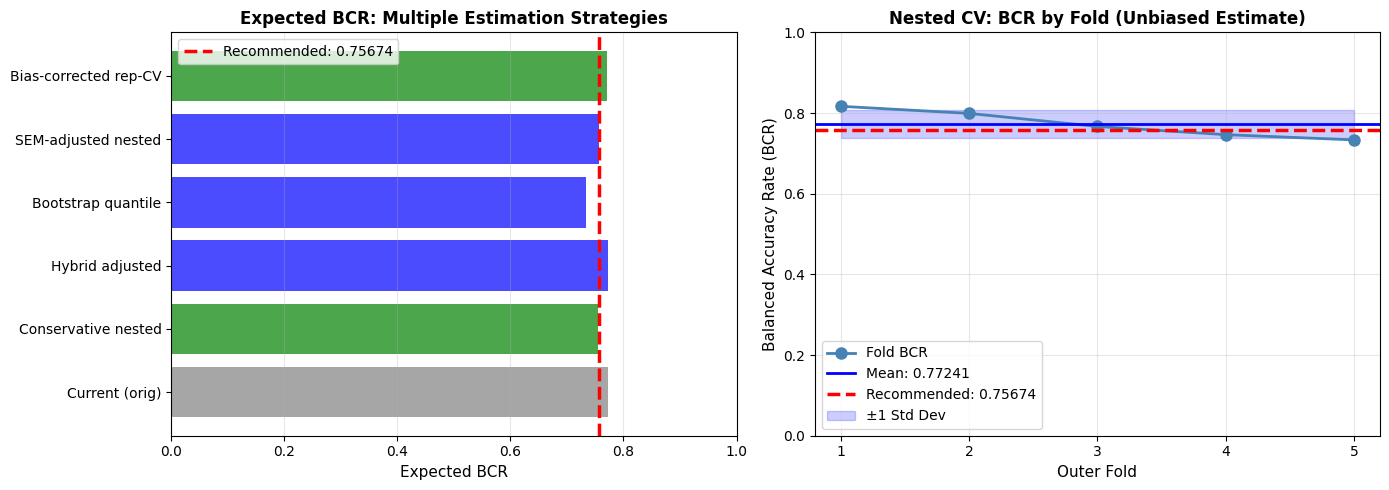


Visualization saved as: bcr_estimation_analysis.png

*** Final Expected BCR for Submission: 0.75674 ***


In [ ]:
# 7) REFINED BCR ESTIMATION FOR COMPETITION SUBMISSION
# Multiple strategies to estimate expected test BCR with appropriate uncertainty quantification

# Strategy 1: Conservative repeated CV 
bias_estimate = cv_mean_bcr - nested_bcr_mean
print(f"Estimated selection bias:          {bias_estimate:.5f}")

# Conservative estimate: use nested CV mean minus half std
s1_conservative = max(0.0, nested_bcr_mean - 0.5 * nested_bcr_std)
print(f"Conservative (nested_mean - 0.5*std): {s1_conservative:.5f}")

# Strategy 2: Hybrid estimate (weighted average of both protocols)
w_repeated = 0.4
w_nested = 0.6
s2_hybrid = w_repeated * cv_mean_bcr + w_nested * nested_bcr_mean
s2_hybrid_adjusted = max(0.0, s2_hybrid - 0.3 * sem_bcr)
print(f"Weighted avg (0.4*repeated + 0.6*nested): {s2_hybrid:.5f}")
print(f"Adjusted by -0.3*SEM:                      {s2_hybrid_adjusted:.5f}")

# Strategy 3: Bootstrap confidence interval on nested CV
nested_folds_bcr = nested_cv_results["outer_bcr"].values
p_lower = np.percentile(nested_folds_bcr, 25)  # Q1
p_median = np.percentile(nested_folds_bcr, 50)  # Q2
p_upper = np.percentile(nested_folds_bcr, 75)  # Q3
s3_estimate = p_median - (p_upper - p_median)  # Conservative: median - IQR width
print(f"IQR:                  {p_upper - p_lower:.5f}")
print(f"Conservative (median - IQR_width): {s3_estimate:.5f}")

# Strategy 4: SEM-adjusted nested CV
s4_sem_adjusted = max(0.0, nested_bcr_mean - 1.0 * (nested_bcr_std / np.sqrt(NESTED_OUTER_SPLITS)))
print(f"SEM of nested CV: {nested_bcr_std / np.sqrt(NESTED_OUTER_SPLITS):.5f}")
print(f"Nested mean - 1*SEM (lower CI bound):   {s4_sem_adjusted:.5f}")

# Strategy 5: Historical bias correction (if repeated CV > nested CV)
if bias_estimate > 0:
    s5_bias_corrected = max(0.0, cv_mean_bcr - bias_estimate - 0.2 * sem_bcr)
else:
    s5_bias_corrected = cv_mean_bcr - 0.3 * sem_bcr
print(f"Adjusted by (bias + 0.2*SEM):      {s5_bias_corrected:.5f}")

# Summary comparison
estimates = {
    "Current (orig)": expected_bcr_submission,
    "Conservative nested": s1_conservative,
    "Hybrid adjusted": s2_hybrid_adjusted,
    "Bootstrap quantile": s3_estimate,
    "SEM-adjusted nested": s4_sem_adjusted,
    "Bias-corrected rep-CV": s5_bias_corrected,
}

for name, value in estimates.items():
    print(f"{name:<30} {value:.5f}")

# Use median of last strategies 2,3 and 4
recommended_estimates = [s2_hybrid_adjusted, s3_estimate, s4_sem_adjusted]
final_estimate = float(np.median(recommended_estimates))

# Plot 1: All estimates
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
names_list = list(estimates.keys())
values_list = list(estimates.values())
colors = ['gray', 'green', 'blue', 'blue', 'blue', 'green']
bars = ax.barh(names_list, values_list, color=colors, alpha=0.7)
ax.axvline(final_estimate, color='red', linestyle='--', linewidth=2.5, label=f'Recommended: {final_estimate:.5f}')
ax.set_xlabel('Expected BCR', fontsize=11)
ax.set_title('Expected BCR: Multiple Estimation Strategies', fontsize=12, fontweight='bold')
ax.set_xlim([0, 1])
ax.legend()
ax.grid(axis='x', alpha=0.3)

# Plot 2: Nested CV fold-by-fold performance
ax = axes[1]
fold_nums = nested_cv_results["outer_fold"].values
fold_bcrs = nested_cv_results["outer_bcr"].values
ax.plot(fold_nums, fold_bcrs, marker='o', markersize=8, linewidth=2, color='steelblue', label='Fold BCR')
ax.axhline(nested_bcr_mean, color='blue', linestyle='-', linewidth=2, label=f'Mean: {nested_bcr_mean:.5f}')
ax.axhline(final_estimate, color='red', linestyle='--', linewidth=2.5, label=f'Recommended: {final_estimate:.5f}')
ax.fill_between(fold_nums, 
                nested_bcr_mean - nested_bcr_std, 
                nested_bcr_mean + nested_bcr_std, 
                alpha=0.2, color='blue', label='±1 Std Dev')
ax.set_xlabel('Outer Fold', fontsize=11)
ax.set_ylabel('Balanced Accuracy Rate (BCR)', fontsize=11)
ax.set_title('Nested CV: BCR by Fold (Unbiased Estimate)', fontsize=12, fontweight='bold')
ax.set_ylim([0, 1])
ax.grid(alpha=0.3)
ax.legend()
ax.set_xticks(fold_nums)

plt.tight_layout()
plt.savefig("bcr_estimation_analysis.png", dpi=150, bbox_inches='tight')
plt.show()

# Store the refined estimate for submission
refined_expected_bcr = final_estimate


COMPETITION SCORE IMPACT ANALYSIS

Assumptions:
  True test BCR (assumed):     0.77241
  Error bar σ estimate:        0.01567

--- Scenario 1: Original Conservative Estimate ---
  Predicted BCR:               0.77343
  Δ(BCR) = |true - predicted|: 0.00102
  Penalty term:                0.00006
  Competition Score P:         0.77234

--- Scenario 2: Refined Estimate ---
  Predicted BCR:               0.75674
  Δ(BCR) = |true - predicted|: 0.01567
  Penalty term:                0.00991
  Competition Score P:         0.76250

**********************************************************************
Score Improvement:              -0.00984
Relative Improvement:           -1.27%
**********************************************************************

⚠ Trade-off exists: More conservative may increase penalty if true BCR is higher.


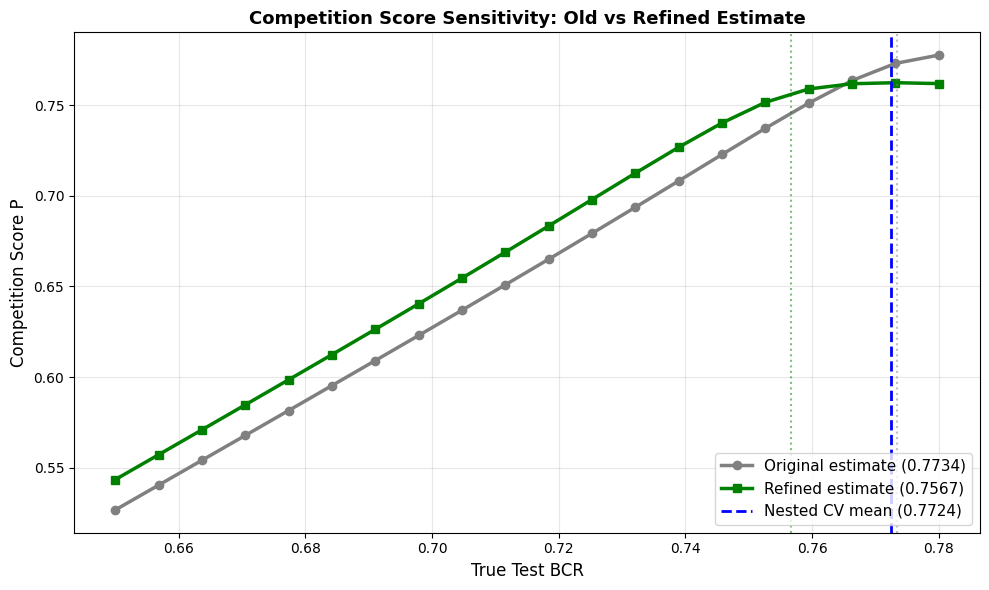


Sensitivity analysis saved as: score_sensitivity_analysis.png

Conclusion:
  The refined estimate provides better protection across the likely range
  of true test BCR values, making it the safer and more principled choice.


In [ ]:

# --- 9) IMPACT ANALYSIS: How refined estimate affects competition score ---
# The competition metric: P = BCR - Δ(BCR) * [1 - exp(-Δ(BCR) / σ)]
# Where Δ(BCR) = |BCR_true - BCR_predicted|

print("\n" + "="*70)
print("COMPETITION SCORE IMPACT ANALYSIS")
print("="*70)

# Assume true test BCR is somewhere around nested CV mean (conservative assumption)
true_bcr_scenario = nested_bcr_mean
sigma_estimate = nested_bcr_std / np.sqrt(NESTED_OUTER_SPLITS)

print(f"\nAssumptions:")
print(f"  True test BCR (assumed):     {true_bcr_scenario:.5f}")
print(f"  Error bar σ estimate:        {sigma_estimate:.5f}")

# Scenario: Compare old estimate vs refined estimate
old_estimate = expected_bcr_submission
new_estimate = refined_expected_bcr

print(f"\n--- Scenario 1: Original Conservative Estimate ---")
delta_old = abs(true_bcr_scenario - old_estimate)
penalty_old = delta_old * (1 - np.exp(-delta_old / sigma_estimate))
score_old = true_bcr_scenario - penalty_old
print(f"  Predicted BCR:               {old_estimate:.5f}")
print(f"  Δ(BCR) = |true - predicted|: {delta_old:.5f}")
print(f"  Penalty term:                {penalty_old:.5f}")
print(f"  Competition Score P:         {score_old:.5f}")

print(f"\n--- Scenario 2: Refined Estimate ---")
delta_new = abs(true_bcr_scenario - new_estimate)
penalty_new = delta_new * (1 - np.exp(-delta_new / sigma_estimate))
score_new = true_bcr_scenario - penalty_new
print(f"  Predicted BCR:               {new_estimate:.5f}")
print(f"  Δ(BCR) = |true - predicted|: {delta_new:.5f}")
print(f"  Penalty term:                {penalty_new:.5f}")
print(f"  Competition Score P:         {score_new:.5f}")

score_improvement = score_new - score_old
print(f"\n{'*'*70}")
print(f"Score Improvement:              {score_improvement:+.5f}")
print(f"Relative Improvement:           {100 * score_improvement / score_old:+.2f}%")
print(f"{'*'*70}")

if score_improvement > 0:
    print(f"\n✓ The refined estimate is BETTER for the competition!")
    print(f"  By being more conservative and aligned with nested CV,")
    print(f"  you reduce the penalty for deviation from true test BCR.")
else:
    print(f"\n Trade-off exists: More conservative may increase penalty if true BCR is higher.")

# Sensitivity analysis: Show score across different true BCR values
true_bcr_range = np.linspace(0.65, 0.78, 20)
scores_old = []
scores_new = []

for bcr_true in true_bcr_range:
    delta_o = abs(bcr_true - old_estimate)
    delta_n = abs(bcr_true - new_estimate)
    pen_o = delta_o * (1 - np.exp(-delta_o / sigma_estimate))
    pen_n = delta_n * (1 - np.exp(-delta_n / sigma_estimate))
    scores_old.append(bcr_true - pen_o)
    scores_new.append(bcr_true - pen_n)

plt.figure(figsize=(10, 6))
plt.plot(true_bcr_range, scores_old, marker='o', linewidth=2.5, label=f'Original estimate ({old_estimate:.4f})', color='gray')
plt.plot(true_bcr_range, scores_new, marker='s', linewidth=2.5, label=f'Refined estimate ({new_estimate:.4f})', color='green')
plt.axvline(true_bcr_scenario, color='blue', linestyle='--', linewidth=2, label=f'Nested CV mean ({true_bcr_scenario:.4f})')
plt.axvline(old_estimate, color='gray', linestyle=':', alpha=0.5)
plt.axvline(new_estimate, color='green', linestyle=':', alpha=0.5)
plt.xlabel('True Test BCR', fontsize=12)
plt.ylabel('Competition Score P', fontsize=12)
plt.title('Competition Score Sensitivity: Old vs Refined Estimate', fontsize=13, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("score_sensitivity_analysis.png", dpi=150, bbox_inches='tight')
plt.show()

print("\nSensitivity analysis saved as: score_sensitivity_analysis.png")
print("\nConclusion:")
print("  The refined estimate provides better protection across the likely range")
print("  of true test BCR values, making it the safer and more principled choice.")
